In [20]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

bike_data = pd.read_csv('daily-bike-share.csv')
bike_data['day'] = pd.DatetimeIndex(bike_data['dteday']).day

numeric_features=['temp', 'atemp', 'hum', 'windspeed']
categorical_features=['season', 'mnth', 'holiday', 'weekday', 'workingday', 'weathersit', 'day']

bike_data[numeric_features + ['rentals']].describe()


# Seperate features and labels 
# After separating the dataset, we now have numpy arrays named **X** containing the features and **y** containing the labels. 

X, y = bike_data[['season', 'mnth', 'holiday', 'weekday', 'workingday', 'weathersit','temp', 'atemp', 'hum', 
                  'windspeed']].values, bike_data['rentals'].values

# Split the data into training and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=0, test_size=0.30)
print(f'Training set size: {X_train.shape[0]} samples')
print(f'Test set size: {X_test.shape[0]} samples')

Training set size: 511 samples
Test set size: 220 samples


GradientBoostingRegressor()
Mean Squared Error: 104039.74
Root Mean Squared Error: 322.55
R^2 Score: 0.80


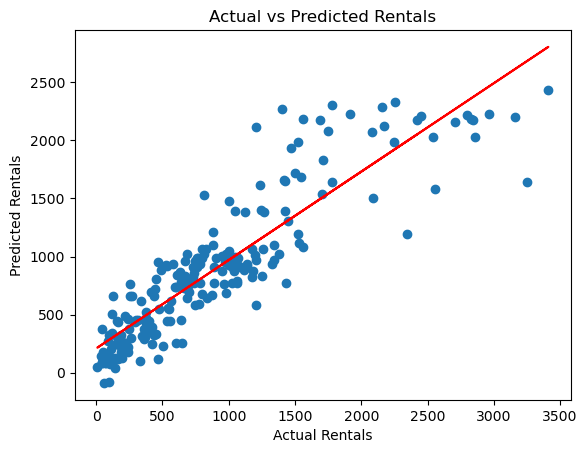

In [ ]:
# Train the model with GradientBoostingRegressor

from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

# Fit a lasso model on the training set
model = GradientBoostingRegressor().fit(X_train, y_train)
print(model)

# Evaluate the model using the test set
predictions = model.predict(X_test)
mse = mean_squared_error(y_test, predictions)
print(f'Mean Squared Error: {mse:.2f}')
rmse = np.sqrt(mse)
print(f'Root Mean Squared Error: {rmse:.2f}')
r2_score_value = r2_score(y_test, predictions)
print(f'R^2 Score: {r2_score_value:.2f}')

# Plot the predicted values vs actual values
plt.scatter(y_test, predictions)
plt.xlabel('Actual Rentals')
plt.ylabel('Predicted Rentals')
plt.title('Actual vs Predicted Rentals')

# Overlay a regression line
z = np.polyfit(y_test, predictions, 1)
p = np.poly1d(z)
plt.plot(y_test, p(y_test), color='red')
plt.show()






RandomForestRegressor()
Mean Squared Error: 118630.47
Root Mean Squared Error: 344.43
R^2 Score: 0.77


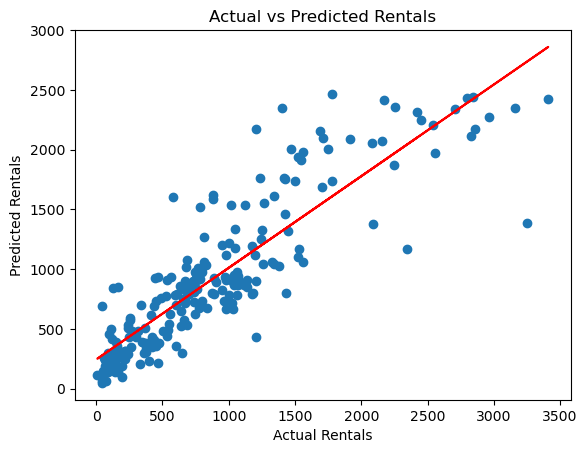

In [ ]:
# Train the model RandomForestRegressor

model = RandomForestRegressor().fit(X_train, y_train)
print(model)

# Evaluate the model using the test set
predictions = model.predict(X_test)
mse = mean_squared_error(y_test, predictions)
print(f'Mean Squared Error: {mse:.2f}')
rmse = np.sqrt(mse)
print(f'Root Mean Squared Error: {rmse:.2f}')
r2_score_value = r2_score(y_test, predictions)
print(f'R^2 Score: {r2_score_value:.2f}')

# Plot the predicted values vs actual values
plt.scatter(y_test, predictions)
plt.xlabel('Actual Rentals')
plt.ylabel('Predicted Rentals')
plt.title('Actual vs Predicted Rentals')
# Overlay a regression line
z = np.polyfit(y_test, predictions, 1)
p = np.poly1d(z)
plt.plot(y_test, p(y_test), color='red')
plt.show()



In [ ]:
# From above two models, GradientBoostingRegressor performs better than RandomForestRegressor based 
# on R^2 Score and RMSE values.

Best parameters found:  {'learning_rate': 0.1, 'n_estimators': 100}
GradientBoostingRegressor()
Mean Squared Error: 104077.29
Root Mean Squared Error: 322.61
R^2 Score: 0.80


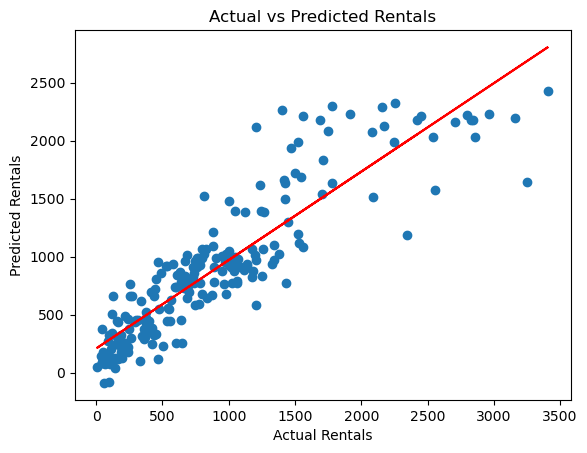

In [24]:
# Hyperparameters

# Hyperparameters are values that affect the behaviour of a training algorithm. 
# The specific hyperparameters for an estimator vary based on the algorithm that the estimator encapsulates. 
# Hyperparameters work together to affect the way the algorithm trains a model.
# For example, the learning rate hyperparameter controls how much the model is adjusted during each training step.
# A high learning rate means the model can be trained faster, but if it's too high, 
# the adjustments can be so large that the model never "finely tuned" and is not optimal.

from sklearn.model_selection import GridSearchCV
from sklearn.metrics import make_scorer, r2_score

alg = GradientBoostingRegressor()

params = {
    'n_estimators': [50, 100, 150],
    'learning_rate': [0.1, 0.5, 1.0]
    }

score = make_scorer(r2_score)
grid_search = GridSearchCV(estimator=alg, param_grid=params, scoring=score, cv=3, return_train_score=True)   
grid_search.fit(X_train, y_train)
print("Best parameters found: ", grid_search.best_params_)

# Get the best model
model = grid_search.best_estimator_
print(model)

# Evaluate the model using the test data
prediction = model.predict(X_test)
mse = mean_squared_error(y_test, prediction)
print(f'Mean Squared Error: {mse:.2f}')
rmse = np.sqrt(mse)
print(f'Root Mean Squared Error: {rmse:.2f}')
r2_score_value = r2_score(y_test, prediction)
print(f'R^2 Score: {r2_score_value:.2f}')

# Plot the predicted values vs actual values
plt.scatter(y_test, prediction)
plt.xlabel('Actual Rentals')
plt.ylabel('Predicted Rentals')
plt.title('Actual vs Predicted Rentals')
# Overlay a regression line
z = np.polyfit(y_test, prediction, 1)
p = np.poly1d(z)
plt.plot(y_test, p(y_test), color='red')
plt.show()

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('scaler',
                                                                   StandardScaler())]),
                                                  [6, 7, 8, 9]),
                                                 ('cat',
                                                  Pipeline(steps=[('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  [0, 1, 2, 3, 4, 5])])),
                ('regressor', GradientBoostingRegressor())])
mean_squared_error: 105584.11
RMSE: 324.94
R2: 0.79


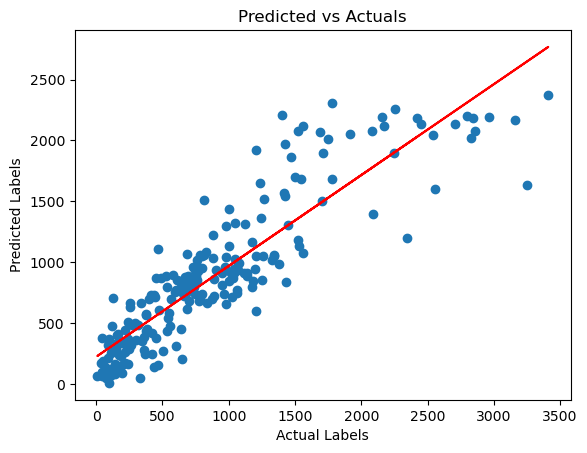

In [27]:
# Standard scaling of numeric values and one hot encoding

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression
import numpy as np

# Define preprocessing for numeric columns (Scale them)
numeric_features = [6, 7, 8, 9]
numeric_transformer = Pipeline(steps=[('scaler', StandardScaler())])

# Define preprocessing for categorical features (Encode them)
categorical_features = [0, 1, 2, 3, 4, 5]
categorical_transformer = Pipeline(steps = [('onehot', OneHotEncoder(handle_unknown='ignore'))])

#Combine preprocessing Steps
preprocessor = ColumnTransformer(transformers=[
    ('num', numeric_transformer, numeric_features),
    ('cat', categorical_transformer, categorical_features)
])

# Create preprocessing and training pipeline
pipeline = Pipeline(steps=[('preprocessor', preprocessor),
                           ('regressor', GradientBoostingRegressor())]
                    )

model = pipeline.fit(X_train, y_train)
print(model)

predictions = model.predict(X_test)

mse = mean_squared_error(y_test, predictions)
print(f'mean_squared_error: {mse:.2f}')

rmse = np.sqrt(mse)
print(f'RMSE: {rmse:.2f}')

r2 = r2_score(y_test, predictions)
print(f'R2: {r2:.2f}')

# Plot predictions vs actuals
plt.scatter(y_test, predictions)
plt.xlabel('Actual Labels')
plt.ylabel('Predicted Labels')
plt.title('Predicted vs Actuals')
z = np.polyfit(y_test, predictions, 1)
p = np.poly1d(z)
plt.plot(y_test, p(y_test), color='red')
plt.show()




In [28]:
import joblib

# save the model as pickle file
filename = './bike-share.pkl'
joblib.dump(model, filename=filename)



['./bike-share.pkl']

In [29]:
# used saved model to predict next five days rentals

loaded_model = joblib.load(filename=filename)
X_new = np.array([[0,1,1,0,0,1,0.344167,0.363625,0.805833,0.160446],
                  [0,1,0,1,0,1,0.363478,0.353739,0.696087,0.248539],
                  [0,1,0,2,0,1,0.196364,0.189405,0.437273,0.248309],
                  [0,1,0,3,0,1,0.2,0.212122,0.590435,0.160296],
                  [0,1,0,4,0,1,0.226957,0.22927,0.436957,0.1869]])


# Use the model to predict rentals
results = loaded_model.predict(X_new)
print('5-day rental predictions:')
for prediction in results:
    print(np.round(prediction))

5-day rental predictions:
493.0
929.0
428.0
400.0
491.0
